# Proyecto 2: Regresión Lineal Múltiple

**Carrera:** Tecnicatura Universitaria en Tecnologías de Programación

**Materia:** Programación Python Avanzada

**Integrantes:** Olivera Yohana y Urriola Itziar

**Dataset:** Software Developer Salary Prediction 

**Fuente:** Kaggle.com

**Link Dataset:** https://www.kaggle.com/datasets/nudratabbas/software-developer-salary-prediction-dataset

**Link Repositorio GitHub:** https://github.com/Itz-U/Proyecto2_Olivera_Urriola_UPSO-Salliquelo.git

### Descripción del dataset

El dataset, contiene información sobre los salarios de desarrolladores de software y distintas características de su perfil profesional.

Está compuesto por 50.000 registros y 7 variables, distribuidos originalmente en dos archivos: train.csv con 40.000 registros y test.csv con 10.000 registros.

Entre las variables se encuentran los años de experiencia profesional, el país de residencia, el nivel educativo, los lenguajes de programación, los frameworks utilizados y el tamaño de la empresa. Además, incluye el salario expresado en dólares estadounidenses (salary_usd), que será nuestra variable objetivo.

### Justificación de la elección

Se eligió este dataset ya que se vincula con el campo de la programación, área correspondiente a nuestra formación profesional, y permite analizar cómo distintas características profesionales pueden influir en los salarios de los desarrolladores de software.

Asimismo, cuenta con una cantidad considerable de registros y variables que pueden utilizarse para desarrollar un Modelo de Regresión Lineal Múltiple implementando Python. Resulta de interés investigar qué factores presentan una mayor relación con el salario y en qué medida es posible estimarlo a partir de ellos.

### Objetivo de predicción

El objetivo es desarrollar un modelo de regresión lineal múltiple que permita predecir el salario de un desarrollador de software en dólares, utilizando variables relacionadas con su experiencia laboral, formación académica y características profesionales.

A partir del modelo, buscamos evaluar la precisión de las predicciones, identificar las variables con mayor influencia sobre el salario y comparar los resultados obtenidos con los datos de entrenamiento y test.

### Diccionario de variables

| Columna | Tipo de Dato | Descripción |
|--------|--------------|-------------|
| experience| int64 | Años de experiencia profesional en programación. |
| country | str | País de residencia del desarrollador. |
| education | str | Nivel más alto de educación formal alcanzado. |
| languages | str | Principales lenguajes de programación utilizados. |
| frameworks | str | Principales frameworks utilizados. |
| company_size | str | Cantidad de empleados de la empresa. |
| salary_usd | int64 | Variable objetivo: salario en dólares estadounidenses que se busca predecir. |

## Parte 1: Análisis exploratorio de datos

### **Importación de librerías y exploración inicial**


Se importaron las librerías necesarias para trabajar con los datos, realizar cálculos y generar visualizaciones.

El dataset original está dividido en dos archivos: train.csv y test.csv. Para este proyecto, se decidió unificar ambos archivos en un único DataFrame con el fin de trabajar con la totalidad de los registros disponibles y, posteriormente, realizar una división aleatoria propia entre entrenamiento y prueba. Esta decisión se adoptó para evitar posibles sesgos asociados a una partición predefinida de los datos y para que el desempeño del modelo no dependa de una división ajena al estudio. De este modo, se busca que la evaluación del modelo sea más objetiva y representativa, no artificialmente favorable, sino que refleje de manera más realista su capacidad de predicción.

In [24]:
# Importamos las librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor


# Cargamos los archivos del dataset
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

# Unificamos ambos archivos
df_original = pd.concat([df_train, df_test], ignore_index=True)

# Generamos una copia para trabajar sin alterar el original
df = df_original.copy()

Transformamos los nombres de las columnas al español, para facilitar el uso y el análisis

In [25]:
df = df.rename(columns={
    "experience": "experiencia",
    "country": "pais",
    "education": "educacion",
    "languages": "lenguajes",
    "company_size": "tamano_empresa",
    "salary_usd": "salario_usd"
})

print(df.columns.tolist())
df.head()

['experiencia', 'pais', 'educacion', 'lenguajes', 'frameworks', 'tamano_empresa', 'salario_usd']


,experiencia,pais,educacion,lenguajes,frameworks,tamano_empresa,salario_usd
0,34,Germany,Masters,"Rust, JavaScript","Vue, ASP.NET",201-1000,172292
1,9,UK,Masters,"C#, JavaScript","Ruby on Rails, Spring",201-1000,82311
2,8,USA,Some College,"C++, Go","Vue, React",5000+,109637
3,29,USA,Masters,"C++, Ruby","Spring, Angular",11-50,214386
4,7,USA,Bachelors,"C#, Rust","React, Express",1-10,107584


Utilizamos **`.shape[ ]`** para conocer las dimensiones del dataset, es decir cuantas filas y columnas tiene.

In [26]:
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas")

Dimensiones del dataset: 50000 filas y 7 columnas


Con el método **`.info( )`** obtenemos el nombre de las columnas, un conteo de valores NO nulos y el tipo de dato que contiene cada columna.

In [27]:
print("Información general y tipos de datos:")
df.info()

Información general y tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   experiencia     50000 non-null  int64
 1   pais            50000 non-null  str  
 2   educacion       50000 non-null  str  
 3   lenguajes       50000 non-null  str  
 4   frameworks      50000 non-null  str  
 5   tamano_empresa  50000 non-null  str  
 6   salario_usd     50000 non-null  int64
dtypes: int64(2), str(5)
memory usage: 2.7 MB


En la información anterior notamos que:

* El dataset no presenta datos nulos

Utilizamos **`.duplicated().sum()`** para comprobar si existen registros completamente duplicados en el dataset unificado.

In [28]:
print("Registros duplicados:", df.duplicated().sum())

Registros duplicados: 0


**Conclusión sobre la calidad de datos:**

* Como muestra la exploración inicial el dataset es robusto ya que cuenta con un total de 50.000 registros. 
* Los tipos de datos son coherentes con la información que representan en la mayoría de las columnas, aunque variables como "lenguajes" y "frameworks", presentan muliples valores y la variable "tamano_empresa" esta expresada en rangos, lo cual nos indica que deberemos tomar decisiones al momento de su utilización en la siguiente etapa
* A nivel de completitud, consideramos que tiene una alta calidad, no se detectaron valores nulos, y posterior a la unificación de los dataset, no se registraron valores duplicados.

### **Análisis de variables** 

#### Variables Categóricas y Numéricas a analizar

Para desarrollar nuestro modelo de regresión lineal múltiple, analizaremos las variables disponibles en el dataset y su posible relación con el salario de los desarrolladores de software.

**Variables numéricas:**

* experiencia: Años de experiencia profesional del desarrollador.
* salario_usd: Salario expresado en dólares estadounidenses. Es nuestra variable objetivo (Y).

**Variables categóricas:**

* pais: País de residencia del desarrollador.
* educacion: Nivel educativo alcanzado.
* lenguajes: Lenguajes de programación utilizados.
* frameworks: Frameworks utilizados.
* tamano_empresa: Tamaño de la empresa donde trabaja.

Analizaremos sus distribuciones y relaciones para comprender mejor los datos e identificar qué características podrían resultar útiles para predecir el salario.

#### Estadísticas descriptivas

Utilizamos el método **`describe()`** para obtener un resumen estadístico de las variables numéricas, incluyendo la media, desviación estándar, valores mínimos y máximos, mediana y cuartiles.

Esto nos permitirá comprender la distribución de los años de experiencia y los salarios de los desarrolladores.

In [29]:
print("Estadísticas dscriptivas de variables numéricas:")
df.describe()

Estadísticas dscriptivas de variables numéricas:


,experiencia,salario_usd
count,50000.000000,50000.000000
mean,19.884320,131689.690060
std,11.868243,46451.633373
min,0.000000,12024.000000
25%,10.000000,98032.750000
50%,20.000000,130396.000000
75%,30.000000,164357.250000
max,40.000000,280900.000000


**Interpretación:**

Los desarrolladores presentan un promedio de **19,88 años de experiencia**, con valores comprendidos entre 0 y 40 años. La mediana es de 20 años, lo que indica que la mitad de los registros corresponde a desarrolladores con 20 años de experiencia o menos.

En cuanto al salario, encontramos un promedio de **131.689,69 USD** y una mediana de **130.396 USD**. Ambos valores son relativamente cercanos, aunque existe una dispersión considerable, reflejada en una desviación estándar de 46.451,63 USD.

Los salarios varían entre 12.024 y 280.900 USD, por lo que resulta interesante analizar su distribución y relación con las características profesionales de los desarrolladores.

#### Distribución de las variables numéricas

**Distribución de la experiencia profesional**

Utilizamos un histograma para visualizar cómo se distribuyen los años de experiencia entre los desarrolladores. Además, incorporamos líneas que representan la media y la mediana para facilitar su interpretación.

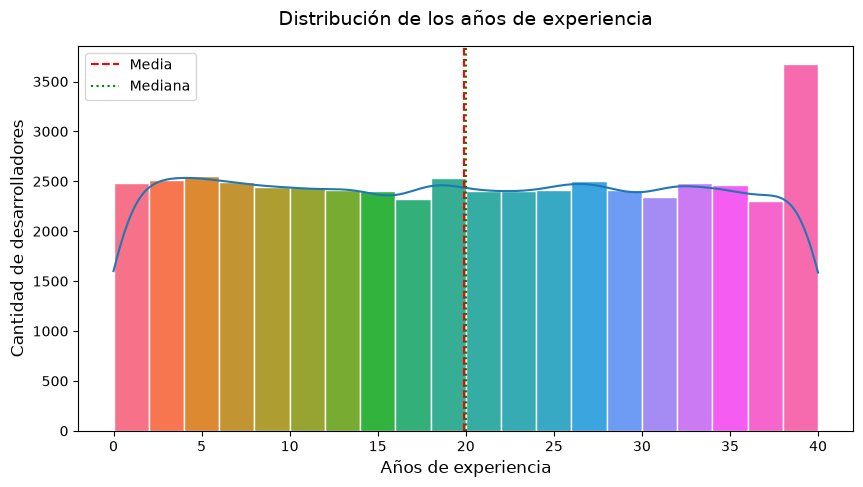

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df,
    x="experiencia",
    bins=20,
    kde=True,
    edgecolor="white",
    linewidth=1,
    ax=ax
)

# Aplicamos la paleta HUSL
paleta_hist = sns.color_palette("husl", len(ax.patches))

for i, barra in enumerate(ax.patches):
    barra.set_facecolor(paleta_hist[i % len(paleta_hist)])

# Media y mediana
plt.axvline(df["experiencia"].mean(), color="red",
            linestyle="--", label="Media")

plt.axvline(df["experiencia"].median(), color="green",
            linestyle=":", label="Mediana")

plt.title("Distribución de los años de experiencia", fontsize=14, pad=15)
plt.xlabel("Años de experiencia", fontsize=12)
plt.ylabel("Cantidad de desarrolladores", fontsize=12)
plt.legend()
plt.show()

**Distribución de los salarios**

Utilizamos un histograma para analizar la frecuencia de los distintos niveles salariales. Incluimos la media y la mediana para identificar dónde se concentran los valores y observar posibles asimetrías en su distribución.

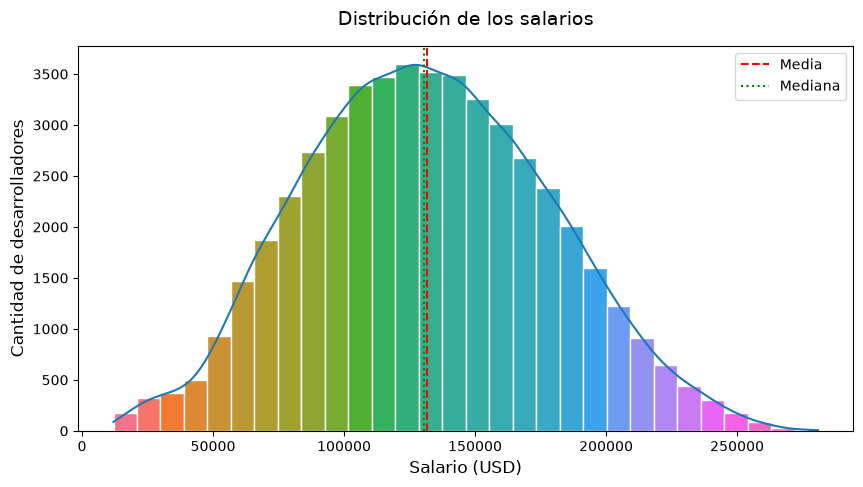

In [31]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df,
    x="salario_usd",
    bins=30,
    kde=True,
    edgecolor="white",
    linewidth=1,
    ax=ax
)

# Aplicamos la paleta HUSL
paleta_hist = sns.color_palette("husl", len(ax.patches))

for i, barra in enumerate(ax.patches):
    barra.set_facecolor(paleta_hist[i % len(paleta_hist)])

# Media y mediana
plt.axvline(df["salario_usd"].mean(), color="red",
            linestyle="--", label="Media")

plt.axvline(df["salario_usd"].median(), color="green",
            linestyle=":", label="Mediana")

plt.title("Distribución de los salarios", fontsize=14, pad=15)
plt.xlabel("Salario (USD)", fontsize=12)
plt.ylabel("Cantidad de desarrolladores", fontsize=12)
plt.legend()
plt.show()

#### Análisis de las variables categóricas

**Exploración de variables categóricas**

Utilizamos nunique() para identificar la cantidad de valores distintos que presenta cada variable categórica. Esto nos permitirá conocer su diversidad y evaluar posteriormente qué tratamiento necesitarán para incorporarlas al modelo.

In [32]:
# Cantidad de valores únicos por variable categórica
categoricas = [
    "pais", "educacion", "lenguajes",
    "frameworks", "tamano_empresa"
]

df[categoricas].nunique()

pais               10
educacion           5
lenguajes         100
frameworks        100
tamano_empresa      6
dtype: int64

**Distribución de las variables categóricas**

Mediante gráficos de barras analizamos la cantidad de desarrolladores registrados según su país de residencia, nivel educativo y tamaño de empresa.

Esto nos permitirá identificar qué categorías tienen mayor representación dentro del dataset.

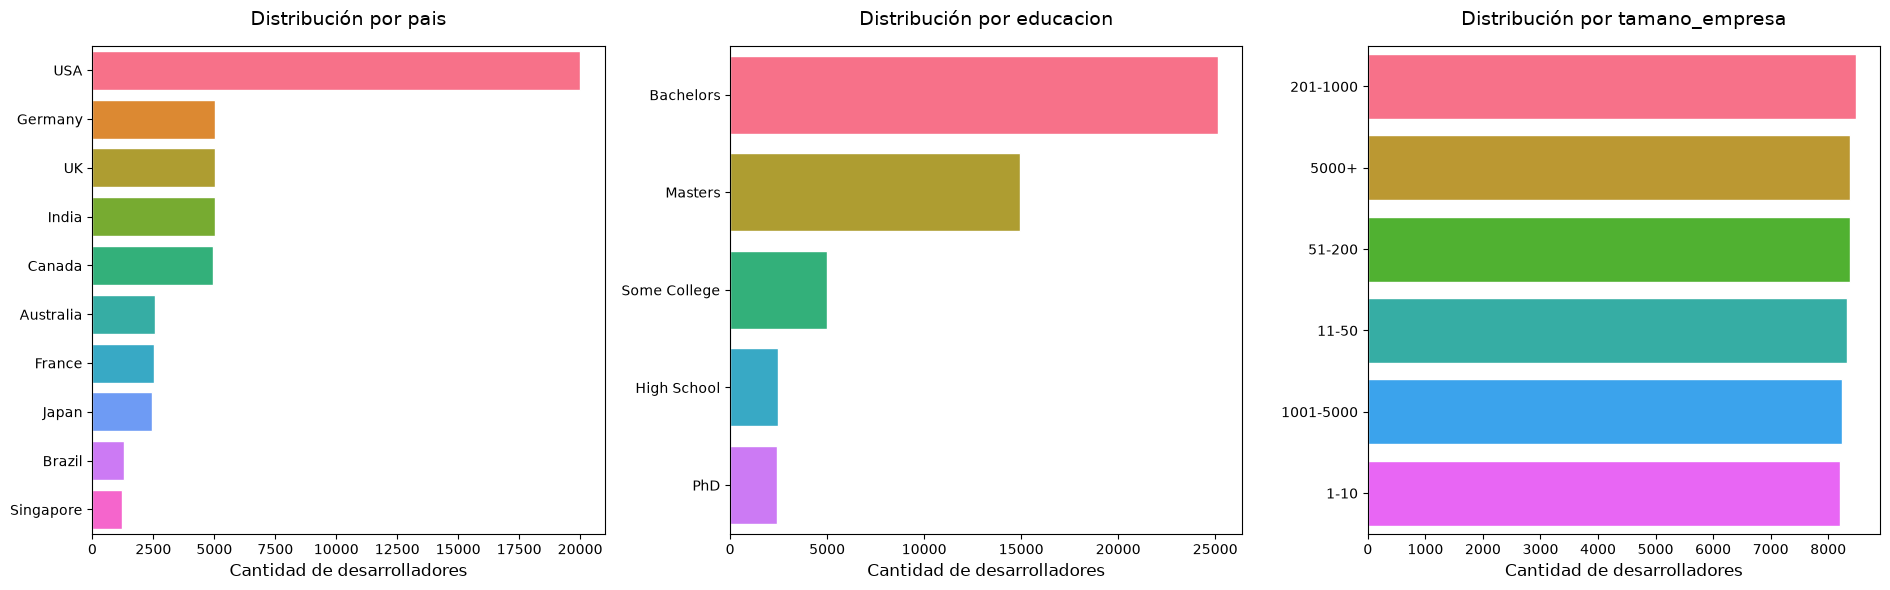

In [33]:
# Variables categóricas a visualizar
variables = ["pais", "educacion", "tamano_empresa"]

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, variable in zip(axes, variables):

    frecuencias = df[variable].value_counts()

    sns.barplot(
        x=frecuencias.values,
        y=frecuencias.index,
        color="steelblue",
        edgecolor="white",
        linewidth=1,
        ax=ax
    )

    # Paleta HUSL
    paleta_barras = sns.color_palette("husl", len(ax.patches))

    for i, barra in enumerate(ax.patches):
        barra.set_facecolor(paleta_barras[i])

    ax.set_title(f"Distribución por {variable}", fontsize=14, pad=15)
    ax.set_xlabel("Cantidad de desarrolladores", fontsize=12)
    ax.set_ylabel("")

plt.tight_layout()
plt.show()


**Relación entre experiencia profesional y salario**

Utilizamos un gráfico de dispersión (scatter plot) para analizar la relación entre los años de experiencia y el salario de los desarrolladores.

Cada punto representa un registro del dataset. El objetivo es observar si existe una tendencia creciente o decreciente y si la relación entre ambas variables presenta un comportamiento aproximadamente lineal.

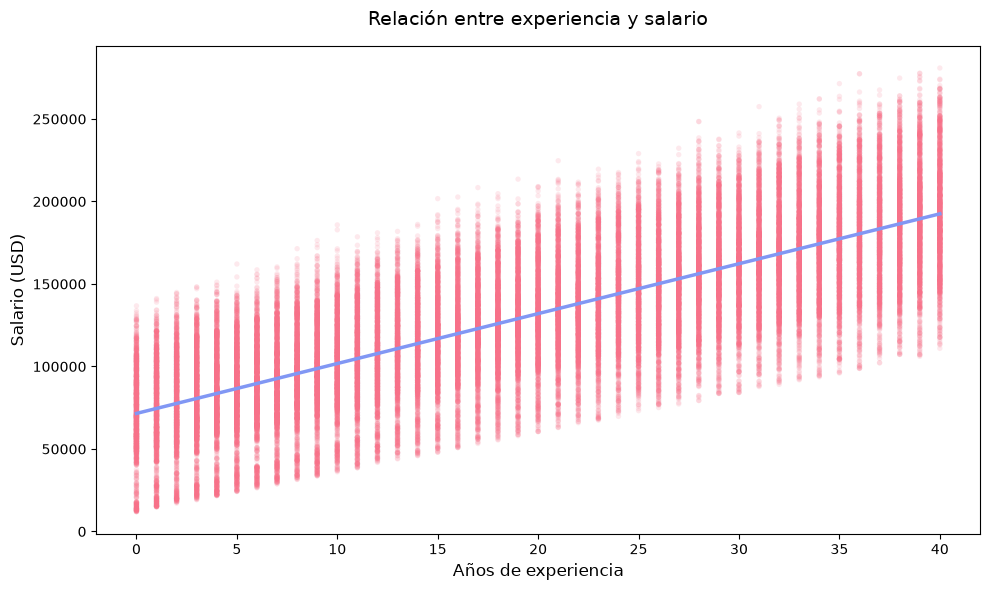

In [34]:
fig, ax = plt.subplots(figsize=(10, 6))

# Paleta HUSL
color_puntos = sns.color_palette("husl", 7)[0]
color_linea = sns.color_palette("husl", 7)[5]

sns.regplot(
    data=df,
    x="experiencia",
    y="salario_usd",
    scatter_kws={
        "alpha": 0.15,
        "s": 15,
        "color": color_puntos,
        "edgecolors": "none"
    },
    line_kws={
        "color": color_linea,
        "linewidth": 2.5
    },
    ci=None,
    ax=ax
)

plt.title("Relación entre experiencia y salario", fontsize=14, pad=15)
plt.xlabel("Años de experiencia", fontsize=12)
plt.ylabel("Salario (USD)", fontsize=12)

plt.tight_layout()
plt.show()

**Coeficiente de correlación de Pearson**

Calculamos el coeficiente de correlación entre experiencia y salario

In [35]:
# Correlación entre experiencia y salario
correlacion = df["experiencia"].corr(df["salario_usd"])

print(f"Correlación de Pearson: {correlacion:.4f}")


Correlación de Pearson: 0.7727


**Interpretación:**

El coeficiente de correlación de Pearson obtenido es de **0,7727**, lo que indica una relación lineal positiva relativamente fuerte entre los años de experiencia y el salario.

Esto significa que, dentro del dataset, los desarrolladores con mayor experiencia tienden a presentar salarios más elevados.

Este resultado sugiere que la experiencia profesional podría ser una variable predictora importante para nuestro modelo de regresión lineal múltiple. Sin embargo, la correlación no implica causalidad ni garantiza por sí sola una buena predicción.

#### Matriz de correlación

Utilizamos una matriz de correlación para visualizar la intensidad y dirección de las relaciones lineales entre las variables numéricas del dataset.

Por el momento, analizamos únicamente `experiencia` y `salario_usd`, ya que las variables categóricas todavía no han sido transformadas.

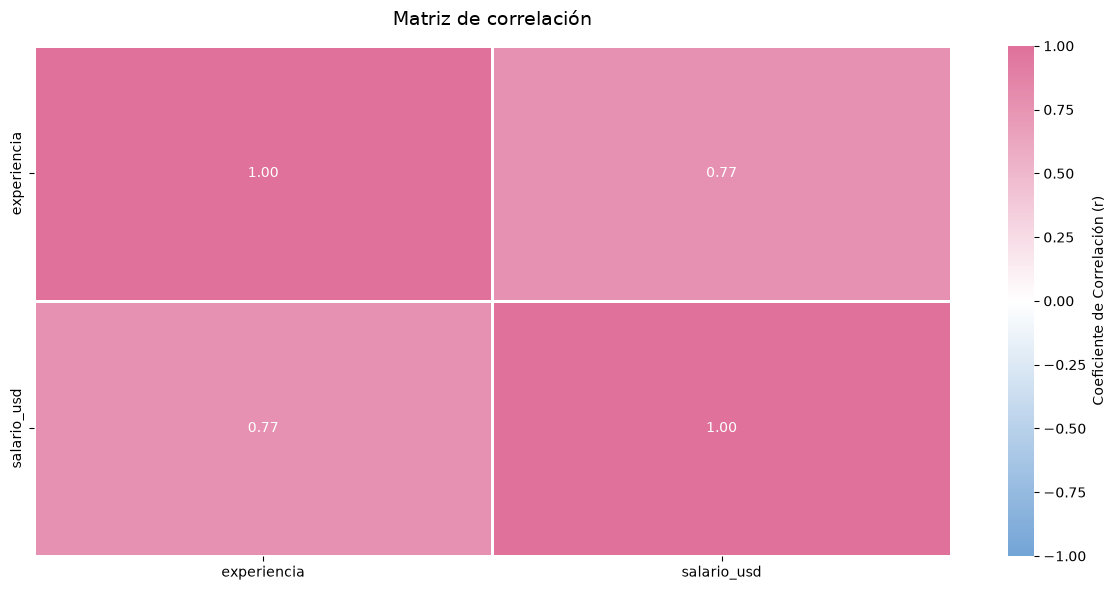

In [36]:
# Importamos la clase LinearSegmentedColormap para crear un mapa de colores personalizado
from matplotlib.colors import LinearSegmentedColormap

plt.figure(figsize=(12, 6))

# Seleccionamos las variables numéricas
numericas = df[["experiencia", "salario_usd"]]

# Calculamos la matriz de correlación
matriz_corr = numericas.corr()

# Definimos paleta de colores
color_negativo = '#73A4D6'  
color_neutro = '#FFFFFF'    
color_positivo = '#DF719A'  

# Creamos una variable para la paleta de colores 
mi_gradiente = LinearSegmentedColormap.from_list('custom_cmap', [color_negativo, color_neutro, color_positivo])

# Generamos el Heatmap
sns.heatmap(
    matriz_corr, 
    annot=True, 
    fmt='.2f', 
    cmap=mi_gradiente, 
    vmin=-1, 
    vmax=1, 
    linewidths=0.8,
    cbar_kws={'label': 'Coeficiente de Correlación (r)'}
)

plt.title("Matriz de correlación", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

#### Relación entre lenguajes de programación y salario

Consideramos interesante analizar si existen diferencias salariales entre los desarrolladores según los lenguajes de programación que utilizan.

Debido a que la columna lenguajes contiene múltiples tecnologías por registro, separaremos los lenguajes para analizarlos individualmente.

Posteriormente, calcularemos el salario promedio y la mediana correspondientes a cada lenguaje, con el objetivo de identificar posibles diferencias salariales y evaluar su utilidad como variables predictoras.

In [37]:

# Separamos los lenguajes y eliminamos repeticiones
df["lista_lenguajes"] = df["lenguajes"].apply(
    lambda texto: list(dict.fromkeys(
        lenguaje.strip() for lenguaje in texto.split(",")
    ))
)

# Creamos una tabla para analizar cada lenguaje
df_lenguajes = df[["lista_lenguajes", "salario_usd"]].explode(
    "lista_lenguajes"
)

df_lenguajes.head()


,lista_lenguajes,salario_usd
0,Rust,172292
0,JavaScript,172292
1,C#,82311
1,JavaScript,82311
2,C++,109637


In [38]:

# Calculamos estadísticas salariales por lenguaje
salarios_lenguajes = (
    df_lenguajes.groupby("lista_lenguajes")["salario_usd"]
    .agg(["count", "mean", "median"])
    .sort_values(by="mean", ascending=False)
    .round(2)
)

# Renombramos las columnas
salarios_lenguajes.columns = [
    "Desarrolladores",
    "Salario promedio",
    "Salario mediano"
]

display(salarios_lenguajes)


,Desarrolladores,Salario promedio,Salario mediano
lista_lenguajes,,,
Rust,9475,132481.62,130485.0
Swift,9520,131993.25,130826.5
Go,9472,131957.55,130399.0
C#,9395,131923.27,131049.0
Python,9669,131750.88,131194.0
Java,9485,131641.51,130214.0
Ruby,9515,131452.69,129942.0
PHP,9434,131399.85,130216.0
C++,9540,130857.40,129489.0


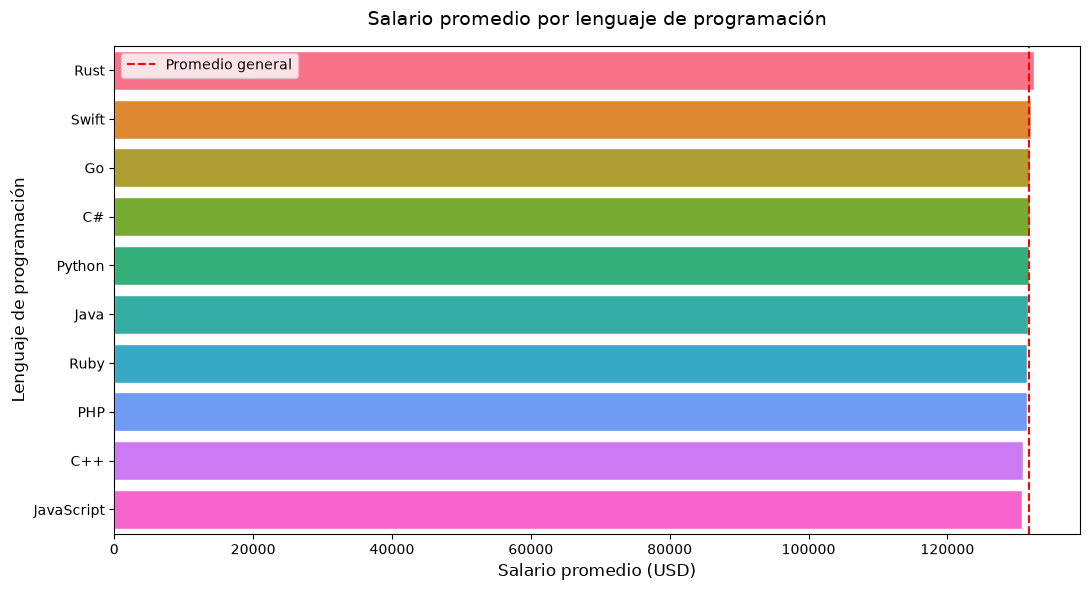

In [39]:

fig, ax = plt.subplots(figsize=(11, 6))

# Ordenamos los salarios de mayor a menor
datos_grafico = salarios_lenguajes.sort_values(
    by="Salario promedio", ascending=False
)

sns.barplot(
    data=datos_grafico,
    x="Salario promedio",
    y=datos_grafico.index,
    color="steelblue",
    edgecolor="white",
    linewidth=1,
    errorbar=None,
    ax=ax
)

# Aplicamos la paleta HUSL
paleta_barras = sns.color_palette("husl", len(ax.patches))

for i, barra in enumerate(ax.patches):
    barra.set_facecolor(paleta_barras[i])

# Línea del salario promedio general
ax.axvline(
    df["salario_usd"].mean(),
    color="red",
    linestyle="--",
    label="Promedio general"
)

plt.title("Salario promedio por lenguaje de programación",
          fontsize=14, pad=15)
plt.xlabel("Salario promedio (USD)", fontsize=12)
plt.ylabel("Lenguaje de programación", fontsize=12)
plt.xlim(left=0)
plt.legend()
plt.tight_layout()
plt.show()


**Interpretación:**

Al comparar los salarios promedio según los lenguajes de programación, observamos que **Rust presenta el promedio más elevado (132.481,60 USD)**, seguido por Swift y Go. Por otro lado, JavaScript presenta el promedio más bajo (130.787,80 USD).

Sin embargo, las diferencias entre los salarios promedio son relativamente pequeñas, por lo que no se observa una relación especialmente marcada entre el lenguaje de programación utilizado y el nivel salarial. Esto sugiere que los lenguajes podrían aportar información adicional al modelo, aunque probablemente sea necesario combinarlos con otras características, como la experiencia profesional, el país y el nivel educativo. Además, los resultados representan asociaciones descriptivas y no permiten afirmar que utilizar un lenguaje determinado provoque un aumento o disminución del salario.

**Conclusión del análisis de variables**


El análisis exploratorio permitió conocer las características principales del dataset e identificar posibles relaciones entre las variables profesionales y el salario de los desarrolladores de software.

Observamos una **correlación positiva relativamente fuerte entre la experiencia profesional y el salario (r = 0,77)**, lo que sugiere que los desarrolladores con mayor experiencia tienden a recibir salarios más elevados.

También analizamos la relación entre los lenguajes de programación y el salario promedio. Encontramos que **Rust presenta el salario promedio más alto (132.481,62 USD)** y JavaScript el más bajo (130.787,77 USD). Sin embargo, las diferencias entre los lenguajes son pequeñas, lo que sugiere que el lenguaje utilizado, por sí solo, podría tener una capacidad predictiva limitada.

Estos resultados indican que la experiencia profesional podría ser una variable importante para nuestro modelo, mientras que los lenguajes de programación podrían aportar información complementaria.

Por este motivo, consideramos necesario incorporar otras características, como el país, el nivel educativo, los frameworks utilizados y el tamaño de la empresa, para evaluar si mejoran la capacidad de predicción del modelo de regresión lineal múltiple.

### **Limpieza y preparación de datos**

#### Verificación de la calidad de los datos

Antes de entrenar el modelo de regresión lineal múltiple, verificamos que los datos se encuentren en condiciones adecuadas para su utilización.
Este paso se realizo en la primera sección del presente informe. En el cual, se observó que el dataset no presenta valores nulos ni registros completamente duplicados, por lo que no es necesario eliminar registros ni aplicar métodos de imputación.

Podemos conservar los 50.000 registros disponibles para continuar con la preparación de las variables.

#### Revisión de categorías

Analizamos los valores que contienen las variables categóricas para identificar cómo están representadas y determinar qué transformaciones serán necesarias antes de utilizarlas en el modelo.

En particular, revisaremos las variables pais, educacion y tamano_empresa, además de los lenguajes de programación y frameworks utilizados.

In [40]:
for columna in ["pais", "educacion", "tamano_empresa"]:
    print(f"\nCategorías de {columna}:")
    print(df[columna].value_counts())



Categorías de pais:
pais
USA          20002
Germany       5032
UK            5010
India         5007
Canada        4938
Australia     2570
France        2533
Japan         2434
Brazil        1281
Singapore     1193
Name: count, dtype: int64

Categorías de educacion:
educacion
Bachelors       25138
Masters         14963
Some College     4995
High School      2469
PhD              2435
Name: count, dtype: int64

Categorías de tamano_empresa:
tamano_empresa
201-1000     8476
5000+        8382
51-200       8379
11-50        8322
1001-5000    8239
1-10         8202
Name: count, dtype: int64


**Interpretación**

Las variables categóricas presentan una cantidad limitada de categorías, lo que facilita su transformación a una representación numérica.

Para incorporarlas al modelo de regresión lineal múltiple, utilizaremos una codificación que permita representar cada categoría sin asignarles un orden numérico artificial.

#### Preparación de frameworks

Al igual que los lenguajes de programación, la variable frameworks contiene múltiples tecnologías dentro de una misma celda, separadas por comas. Para preparar la información, se separó los frameworks en listas individuales, eliminando posibles repeticiones dentro de cada registro. Esto permitirá analizar las tecnologías de manera independiente y preparar su posterior codificación numérica.

In [41]:
# Separamos los frameworks
df["lista_frameworks"] = df["frameworks"].apply(
    lambda texto: list(dict.fromkeys(
        framework.strip() for framework in texto.split(",")
    ))
)

# Visualizamos las tecnologías separadas
df[["lista_lenguajes", "lista_frameworks"]].head()


,lista_lenguajes,lista_frameworks
0,"[Rust, JavaScript]","[Vue, ASP.NET]"
1,"[C#, JavaScript]","[Ruby on Rails, Spring]"
2,"[C++, Go]","[Vue, React]"
3,"[C++, Ruby]","[Spring, Angular]"
4,"[C#, Rust]","[React, Express]"


#### Análisis de frecuencia de frameworks

Se analizó la frecuencia de los diferentes frameworks registrados en el dataset. Para ello, se contabilizó  cada framework individualmente y se representó los resultados mediante un gráfico de barras, con el objetivo de identificar cuáles son los más utilizados por los desarrolladores.

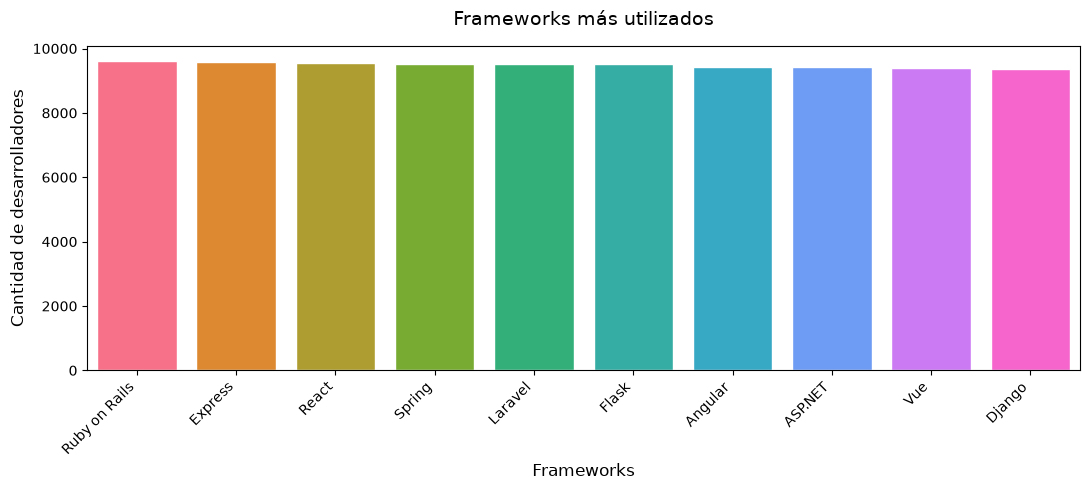

In [42]:
# Contamos la frecuencia de cada framework
frecuencia_frameworks = (
    df["lista_frameworks"]
    .explode()
    .value_counts()
)

fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(
    x=frecuencia_frameworks.index,
    y=frecuencia_frameworks.values,
    color="steelblue",
    edgecolor="white",
    linewidth=1,
    ax=ax
)

# Paleta HUSL
paleta_barras = sns.color_palette("husl", len(ax.patches))

for i, barra in enumerate(ax.patches):
    barra.set_facecolor(paleta_barras[i])

plt.title("Frameworks más utilizados", fontsize=14, pad=15)
plt.xlabel("Frameworks", fontsize=12)
plt.ylabel("Cantidad de desarrolladores", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Interpretación**

El gráfico permitió identificar los frameworks con mayor presencia en el dataset y comparar su frecuencia de utilización entre los desarrolladores. Como cada registro puede contener más de un framework, una persona puede contabilizarse en varias categorías.

Este análisis nos permitió conocer la distribución de las tecnologías utilizadas, aunque su frecuencia no indica necesariamente que estén relacionadas con salarios más elevados.

#### Codificación de variables categóricas

Para poder utilizar las variables categóricas en el modelo de regresión lineal múltiple, se decidió transformar las mismas a variables numéricas. Para ello se utilizará One-Hot Encoding en las variables pais, educacion y tamano_empresa. En el caso de lenguajes y frameworks, se decidió utilizar una codificación binaria por tecnología. La variable experiencia conservará su representación numérica original, mientras que salario_usd será la variable objetivo.

Estas transformaciones se aplicarán después de dividir el dataset en entrenamiento y test, para evitar que la información del conjunto de prueba intervenga en el ajuste del procesamiento.

**Conclusión de la limpieza y preparación de datos**

* El dataset presenta una estructura adecuada para continuar con el desarrollo del modelo, ya que no contiene valores nulos ni registros duplicados.

* Se identificó que las variables relacionadas con el país, nivel educativo y tamaño de empresa son categóricas, mientras que las columnas de lenguajes y frameworks contienen múltiples tecnologías por registro. Para facilitar su análisis, se separó los lenguajes de programación y frameworks en listas individuales, evitando repeticiones dentro de cada registro.

* Finalmente, se definió que las variables categóricas serán transformadas mediante codificación binaria, permitiendo incorporarlas junto con la experiencia profesional al modelo de regresión lineal múltiple.

* La codificación definitiva se realizará después de separar los datos en entrenamiento y test, para garantizar una evaluación adecuada del modelo.

### **Partición de datos y transformación a estructura matricial**

#### Separación de variables predictoras y objetivo

Para desarrollar el modelo de regresión lineal múltiple, se realizó la separación de las variables predictoras (X) de la variable objetivo (Y).

Las variables predictoras corresponden a las características profesionales de los desarrolladores, mientras que **la variable objetivo es salario_usd**, que representa el salario que se busca estimar.

Como variables de entrada del modelo se utilizaron la experiencia, país, nivel educativo, lenguajes de programación, frameworks y el tamaño de empresa.

In [43]:
# Seleccionamos las variables predictoras
X = df[[
    "experiencia",
    "pais",
    "educacion",
    "tamano_empresa",
    "lista_lenguajes",
    "lista_frameworks"
]]

# Seleccionamos la variable objetivo
y = df["salario_usd"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)


Dimensiones de X: (50000, 6)
Dimensiones de y: (50000,)


#### División de los datos en entrenamiento y test

Se utilizó la función train_test_split() de Scikit-learn para dividir aleatoriamente el dataset en dos conjuntos:
- 80 % para entrenamiento: se utilizará para ajustar el modelo de regresión lineal múltiple.
- 20 % para test: se reservará para evaluar su capacidad de predicción con datos que no fueron utilizados durante el entrenamiento.
Se estableció random_state=42 para garantizar que la división sea reproducible y obtener los mismos resultados al ejecutar nuevamente el notebook.

In [44]:
# Dividimos los datos aleatoriamente (80 % - 20 %)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de test:", X_test.shape[0])


Registros de entrenamiento: 40000
Registros de test: 10000


**Interpretación**

El dataset fue dividido aleatoriamente en **40.000 registros para entrenamiento y 10.000 para test**, utilizando una proporción del 80 % y 20 %, respectivamente. Esta separación nos permitirá entrenar el modelo con una parte de los datos y posteriormente evaluar su desempeño con registros diferentes, verificando su capacidad para realizar predicciones sobre datos no utilizados en el entrenamiento.

In [ ]:
tasa_cambio_gbp_usd = 1.30
df["Precio usd"] = (df["Precio"] * tasa_cambio_gbp_usd).round(2)

df.info()

<class 'pandas.DataFrame'>
Index: 27061 entries, 0 to 27074
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id juego                  27061 non-null  int64  
 1   Nombre                    27061 non-null  str    
 2   Fecha de lanzamiento      27061 non-null  str    
 3   Idioma ingles             27061 non-null  int64  
 4   Desarrollador             27061 non-null  str    
 5   Editor                    27061 non-null  str    
 6   Plataformas               27061 non-null  str    
 7   Edad requerida            27061 non-null  int64  
 8   Categorias                27061 non-null  str    
 9   Generos                   27061 non-null  str    
 10  Etiquetas SteamSpy        27061 non-null  str    
 11  Logros                    27061 non-null  int64  
 12  Valoraciones positivas    27061 non-null  int64  
 13  Valoraciones negativas    27061 non-null  int64  
 14  Tiempo promedio de jue

* **índice de satisfacción:** Calculamos la proporción de valoraciones positivas sobre el total de valoraciones: Positivas / (Positivas + Negativas).

In [ ]:
total_valoraciones = df['Valoraciones positivas'] + df['Valoraciones negativas']

# Creamos la columna vacía
df['Indice de satisfaccion'] = np.nan

# Calculamos solo donde hay votos registrados
con_votos = total_valoraciones > 0
df.loc[con_votos, 'Indice de satisfaccion'] = (
    df.loc[con_votos, 'Valoraciones positivas'] / total_valoraciones[con_votos]
).round(4)

# Verificación
df[["Nombre", "Valoraciones positivas", "Valoraciones negativas", "Indice de satisfaccion"]].head()

,Nombre,Valoraciones positivas,Valoraciones negativas,Indice de satisfaccion
0,Counter-Strike,124534,3339,0.9739
1,Team Fortress Classic,3318,633,0.8398
2,Day of Defeat,3416,398,0.8956
3,Deathmatch Classic,1273,267,0.8266
4,Half-Life: Opposing Force,5250,288,0.9480


Para facilitar la comprensión convertimos en porcentaje el índice de valoración

In [ ]:
df["Porcentaje satisfaccion"] = np.nan
con_votos = total_valoraciones > 0

df.loc[con_votos, "Porcentaje satisfaccion"] = (
    (df.loc[con_votos, "Valoraciones positivas"] / total_valoraciones.loc[con_votos]) * 100
).round(2)

# Verificación
df[["Nombre", "Valoraciones positivas", "Valoraciones negativas", "Porcentaje satisfaccion"]].head()

,Nombre,Valoraciones positivas,Valoraciones negativas,Porcentaje satisfaccion
0,Counter-Strike,124534,3339,97.39
1,Team Fortress Classic,3318,633,83.98
2,Day of Defeat,3416,398,89.56
3,Deathmatch Classic,1273,267,82.66
4,Half-Life: Opposing Force,5250,288,94.80


* **Rango de precios:** Clasificamos los juegos en Gratis (0 USD), Económico (hasta 10 USD), Estándar(hasta 30 USD) y Premium (más de 30 USD) usando la función `pd.cut`. 

In [ ]:
# Definimos los intervalos de precios
intervalos_precio = [-0.01, 0.01, 10.0, 30.0, df["Precio usd"].max() + 1]

# Definimos las etiquetas para cada rango de precios
labels_precio = ["Gratis", "Económico", "Estándar", "Premium"]

# Creamos la nueva columna "Rango de precio" usando pd.cut
df["Rango de precio"] = pd.cut(df["Precio usd"], bins=intervalos_precio, labels=labels_precio, right=False)

# Verificación
df[["Nombre", "Precio usd", "Rango de precio"]].head()

,Nombre,Precio usd,Rango de precio
0,Counter-Strike,9.35,Económico
1,Team Fortress Classic,5.19,Económico
2,Day of Defeat,5.19,Económico
3,Deathmatch Classic,5.19,Económico
4,Half-Life: Opposing Force,5.19,Económico


* **Año de lanzamiento:** Para extraer solo el año de la fecha completa, primero convertimos la columna "Fecha de lanzamiento" de `str` a `datetime`, y luego creamos la nueva columna solo con el año de lanzamiento.

In [ ]:
# Convertimos a datetime la columna "Fecha de lanzamiento"
df["Fecha de lanzamiento"] = pd.to_datetime(df["Fecha de lanzamiento"])

# Extraemos el año de lanzamiento y lo almacenamos en una nueva columna
df["Año de lanzamiento"] = df["Fecha de lanzamiento"].dt.year

# Verificación
df[["Nombre", "Fecha de lanzamiento", "Año de lanzamiento"]].head()

,Nombre,Fecha de lanzamiento,Año de lanzamiento
0,Counter-Strike,2000-11-01,2000
1,Team Fortress Classic,1999-04-01,1999
2,Day of Defeat,2003-05-01,2003
3,Deathmatch Classic,2001-06-01,2001
4,Half-Life: Opposing Force,1999-11-01,1999


* **Agrupación por variable categorica**

A continuación, agruparemos los datos para empezar a visualizar tendencias, como la satisfacción por rango de precio o el crecimiento de lanzamientos año a año.

**Promedio de satisfacción por Género Principal**

In [ ]:
agrupacion_genero = df.groupby("Genero principal")["Indice de satisfaccion"].mean().sort_values(ascending=False)

# Verificación
agrupacion_genero.head(10)

Genero principal
Software Training        0.965000
Web Publishing           0.905600
Design & Illustration    0.775196
RPG                      0.747909
Animation & Modeling     0.744202
Adventure                0.739871
Sexual Content           0.730213
Indie                    0.724066
Action                   0.716164
Education                0.713500
Name: Indice de satisfaccion, dtype: float64

**Cantidad de juegos por Plataforma**

In [ ]:
agrupacion_plataforma = df.groupby("Plataformas")["Id juego"].count().sort_values(ascending=False)

# Verificación
agrupacion_plataforma.head(10)

Plataformas
windows              18387
windows;mac;linux     4622
windows;mac           3438
windows;linux          609
mac                      3
mac;linux                1
linux                    1
Name: Id juego, dtype: int64

**Satisfacción promedio segun rango de precio**

In [ ]:
agrupacion_precio = df.groupby('Rango de precio', observed=True)['Indice de satisfaccion'].mean()

# verificación
agrupacion_precio.head(10)

Rango de precio
Gratis       0.719124
Económico    0.700849
Estándar     0.754994
Premium      0.743948
Name: Indice de satisfaccion, dtype: float64

**Cantidad de lanzamientos por año y diferencia porcentual**

In [ ]:
lanzamientos_por_ano = df.groupby('Año de lanzamiento').size().reset_index(name='Cantidad de lanzamientos')

# Se calcula el % de cambio con respecto a la fila anterior
lanzamientos_por_ano['Diferencia porcentual %'] = (lanzamientos_por_ano['Cantidad de lanzamientos'].pct_change() * 100).round(2)

# Verificación
lanzamientos_por_ano.tail(7)


,Año de lanzamiento,Cantidad de lanzamientos,Diferencia porcentual %
16,2013,418,30.62
17,2014,1554,271.77
18,2015,2595,66.99
19,2016,4358,67.94
20,2017,6354,45.80
21,2018,8155,28.34
22,2019,2213,-72.86


In [ ]:
# Verificación de los primeros 10 años de lanzamientos
lanzamientos_por_ano.head(10)

,Año de lanzamiento,Cantidad de lanzamientos,Diferencia porcentual %
0,1997,1,NaN
1,1998,1,0.0
2,1999,2,100.0
3,2000,2,0.0
4,2001,4,100.0
5,2002,1,-75.0
6,2003,3,200.0
7,2004,6,100.0
8,2005,6,0.0
9,2006,48,700.0


**Conclusión de Transformaciones y Agrupaciones**

La limpieza y transformación nos permitió aislar variables clave. La creación del "Índice de satisfacción" unifica las valoraciones positivas y negativas en una sola métrica porcentual más justa de comparar. Por su parte, la agrupación temporal y el cálculo de la "Diferencia porcentual anual" ya nos anticipan un salto masivo en la cantidad de juegos publicados alrededor de 2014, lo cual será fundamental para responder a nuestra tercera pregunta de investigación en la etapa de visualización.

#### Operaciones con NumPy

Si bien se realizaron operaciones con NumPy en las secciones anteriores, por ejemplo en la converción de los precios de GBP a USD, en este apartado nos enfocaremos en la exploración y normalización de variables numéricas utilizando las herramientas que nos brinda Numpy. 
Para lograrlo, transformaremos las variables numéricas principales (Precio usd, Valoraciones positivas y Valoraciones negativas) en arrays y desarrollaremos una función estadística propia. Esta función automatizará el cálculo de métricas de tendencia central y dispersión, incorporando el filtrado de valores nulos. Finalmente, aplicaremos un escalado lineal (Min-Max) para normalizar los precios.

In [ ]:
# Conversión de variables numéricas a arrays de numpy 
arr_precio = df["Precio usd"].to_numpy()
arr_positivas = df["Valoraciones positivas"].to_numpy()
arr_negativas = df["Valoraciones negativas"].to_numpy()

# Función para automatizar metricas descriptivas
def calcular_metricas_numpy(arr, nombre = "Variable"):
    datos = arr[~np.isnan(arr)]

    media = np.mean(datos)
    mediana = np.median(datos)
    desviacion = np.std(datos)
    p25 = np.percentile(datos, 25)
    p75 = np.percentile(datos, 75)
    iqr = p75 - p25
    minimo = np.min(datos)
    maximo = np.max(datos)

    return pd.Series({
        "Variable": nombre,
        "Media": round(media, 2),
        "Mediana": round(mediana, 2),
        "Desviación estándar": round(desviacion, 2),
        "Percentil 25": round(p25, 2),
        "Percentil 75": round(p75, 2),
        "IQR": round(iqr, 2),
        "Mínimo": round(minimo, 2),
        "Máximo": round(maximo, 2)
    })

# Resumen estadístico
tabla_numpy = pd.DataFrame([
    calcular_metricas_numpy(arr_precio, "Precio en USD"),
    calcular_metricas_numpy(arr_positivas, "Valoraciones Positivas"),
    calcular_metricas_numpy(arr_negativas, "Valoraciones Negativas")
])

tabla_numpy.head()

,Variable,Media,Mediana,Desviación estándar,Percentil 25,Percentil 75,IQR,Mínimo,Máximo
0,Precio en USD,7.91,5.19,10.24,2.2,9.35,7.15,0.0,548.59
1,Valoraciones Positivas,1001.04,24.00,18993.27,6.0,126.00,120.00,0.0,2644404.00
2,Valoraciones Negativas,211.12,9.00,4285.97,2.0,42.00,40.00,0.0,487076.00


**Normalización de las variables**

In [ ]:
# Normalización Min-Max de la variable Precio usd al rango [0, 1]
min_val = np.min(arr_precio)
max_val = np.max(arr_precio)
df["Precio_usd_norm"] = (arr_precio - min_val) / (max_val - min_val)

# Verificación
df[["Nombre", "Precio usd", "Precio_usd_norm"]].head()

,Nombre,Precio usd,Precio_usd_norm
0,Counter-Strike,9.35,0.017044
1,Team Fortress Classic,5.19,0.009461
2,Day of Defeat,5.19,0.009461
3,Deathmatch Classic,5.19,0.009461
4,Half-Life: Opposing Force,5.19,0.009461


**Conlusión**

Los resultados de nuestra función revelan una fuerte asimetría en los datos de Steam. En las valoraciones, notamos que la media es muchísimo mayor que la mediana, con una desviación estándar enorme y máximos exorbitantes. Esto indica que hay un pequeño grupo de juegos que son extremadamente populares y concentran la gran mayoría de las reseñas, mientras que el 75% del catálogo apenas supera las 126 reseñas positivas. En cuanto al precio, la normalización nos permite observar la distribución en una escala estándar, confirmando que la mayoría del catálogo se sitúa muy cerca del límite inferior, es decir, la mayoría de los juegos se situan en el rango de precios "económicos", siendo muy raros los títulos que se acercan al valor 1 de nuestra escala normalizada, es decir al rango de juegos "premium".

#### Visualización de datos

En esta sección, generaremos visualizaciones clave para entender la distribución de nuestros datos y responder a las preguntas de investigación planteadas al inicio del proyecto utilizando `matplotlib` y `seaborn`.

In [ ]:
# Definimos tema claro para los gráficos
sns.set_theme(style="whitegrid", palette="muted")

##### **Visualización 1: Análisis de Precios**

Antes de graficar la distribución general de los precios, necesitamos entender si existen valores extremos (outliers). Para ello, aplicamos un gráfico Boxplot para visualizarlos.

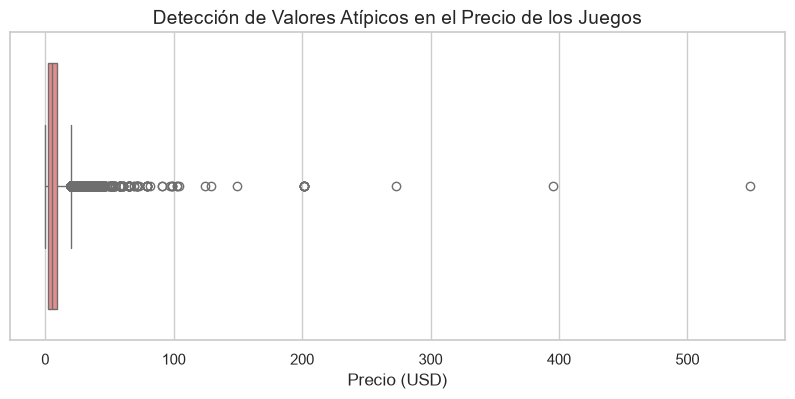

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['Precio usd'], color='lightcoral')
plt.title('Detección de Valores Atípicos en el Precio de los Juegos', fontsize=14)
plt.xlabel('Precio (USD)')
plt.show()

**Conclusión:** Como revela el Boxplot superior, la inmensa mayoría de los juegos cuestan menos de 50 USD. Sin embargo, existen valores atípicos extremos que superan los 400 USD. Si incluimos estos valores en un histograma, el gráfico se comprimiría tanto que no podríamos ver la distribución real. 
Por esta razón, **filtraremos el dataset a juegos con un precio menor o igual a 100 USD**, lo que representa más del 99% de nuestro catálogo.

Ahora analizaremos como se distribuyen los precios del catálogo completo, teniendo en cuenta lo anteriormente mencionado.

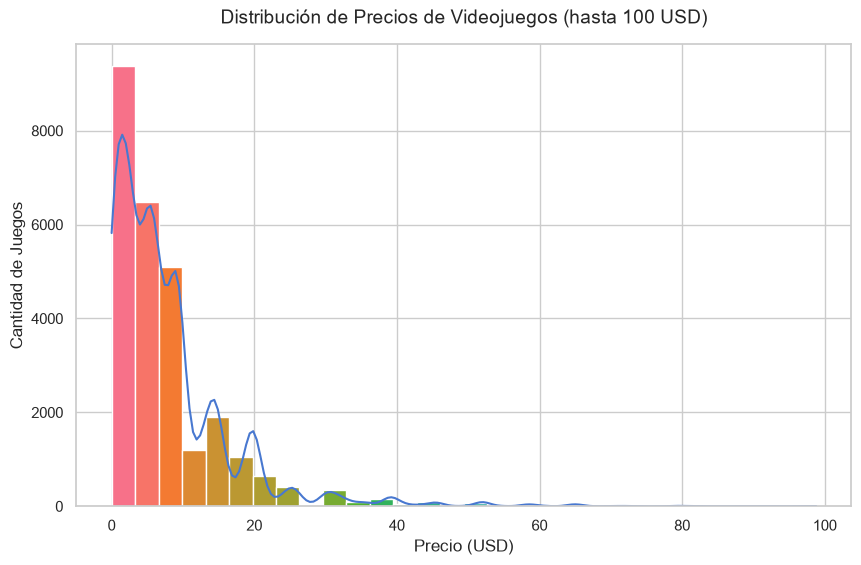

In [ ]:
plt.figure(figsize=(10, 6))

# Filtramos los juegos de más de 100USD para que no se deforme el gráfico
precios_filtrados = df[df["Precio usd"] <= 100]

# Creamos el histograma 
ax = sns.histplot(data=precios_filtrados, x='Precio usd', bins=30, kde=True)

# Configuramos paleta de colores
paleta_hist = sns.color_palette("husl", len(ax.patches))
for i, barra in enumerate(ax.patches):
    barra.set_facecolor(paleta_hist[i % len(paleta_hist)])

plt.title('Distribución de Precios de Videojuegos (hasta 100 USD)', fontsize=14, pad=15)
plt.xlabel('Precio (USD)', fontsize=12)
plt.ylabel('Cantidad de Juegos', fontsize=12)
plt.show()

**Interpretación:** Como podemos comprobar con el gráfico la inmensa mayoría de los títulos en Steam se concentran en el rango de los $0 a $10 USD. La distribución está fuertemente sesgada a la derecha, indicando que los juegos con precios altos o "Premium" son una minoría en el volumen total del catálogo.

##### **Visualización 2: Satisfacción por Género**

**Pregunta de investigación 1: ¿Qué género de videojuego concentra el mayor porcentaje promedio de reseñas positivas por parte de los usuarios?**

Para evitar que géneros con solo 2 o 3 juegos distorsionen el promedio con puntuaciones perfectas, filtraremos el análisis para incluir únicamente aquellos géneros que tengan un mínimo de 100 juegos publicados.

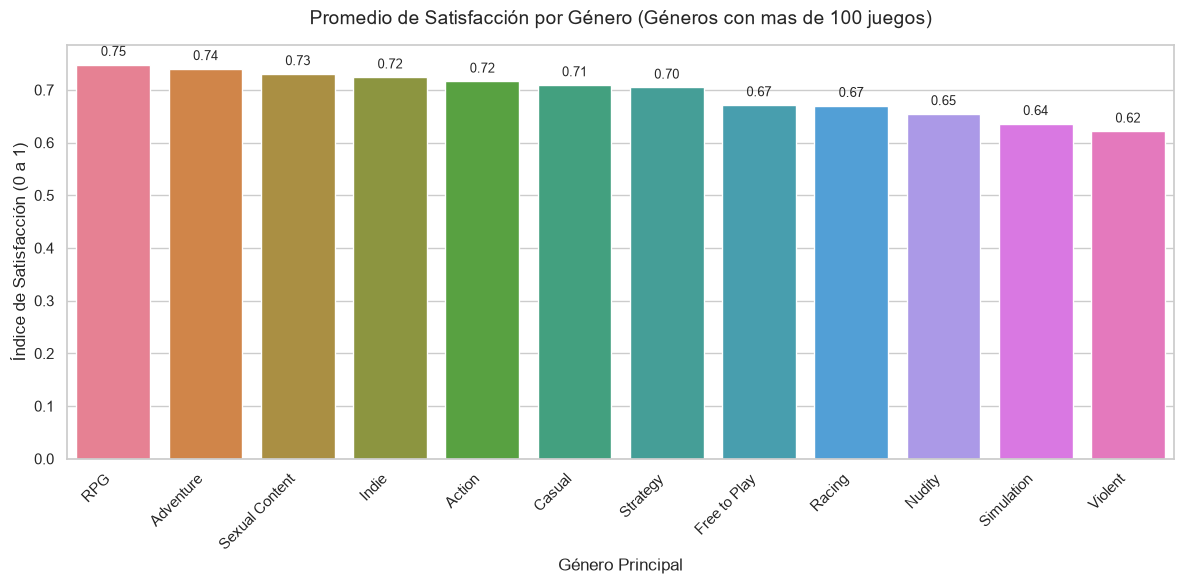

In [ ]:
plt.figure(figsize=(12, 6))

# Conteo de generos principales
conteo_generos = df['Genero principal'].value_counts()

# Filtramos géneros con más de 100 juegos
generos_populares = conteo_generos[conteo_generos > 100].index

# Creamos un nuevo DataFrame con los géneros populares
df_generos = df[df['Genero principal'].isin(generos_populares)]

# Calculamos el promedio de satisfacción por género
satisfaccion_genero = df_generos.groupby('Genero principal')['Indice de satisfaccion'].mean().reset_index()

# Ordenamos de mayor a menor
satisfaccion_genero = satisfaccion_genero.sort_values(by='Indice de satisfaccion', ascending=False)

# Creamos el gráfico de barras
ax = sns.barplot(data=satisfaccion_genero, x='Genero principal', y='Indice de satisfaccion', hue='Genero principal', palette='husl', legend=False)

plt.title('Promedio de Satisfacción por Género (Géneros con mas de 100 juegos)', fontsize=14, pad=15)
plt.xlabel('Género Principal', fontsize=12)
plt.ylabel('Índice de Satisfacción (0 a 1)', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Añadir etiquetas de datos sobre las barras
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.2f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha = 'center', va = 'center', 
                xytext = (0, 9), 
                textcoords = 'offset points',
                fontsize=9)

plt.tight_layout()
plt.show()

**Pregunta de investigación 1: ¿Qué género de videojuego concentra el mayor porcentaje promedio de reseñas positivas por parte de los usuarios?**

**Respuesta:** A partir del análisis comparativo, se determina que el género que lidera el nivel de satisfacción comunitaria en la plataforma es RPG, alcanzando un índice promedio de 0.75, escoltado inmediatamente por Adventure (0.74). Aunque el conjunto general de categorías exhibe un comportamiento favorable con registros que oscilan entre 0.62 y 0.75, los datos revelan que los juegos con fuerte componente narrativo y bases de usuarios fidelizadas logran una mejor valoración que aquellos dependientes de modelos masivos como Free to Play (0.67) o de simulación técnica como Simulation (0.64), los cuales enfrentan mayores exigencias y fricciones por parte de la comunidad.

##### **Visualización 3: Relación entre Precio y Satisfacción**

**Pregunta de investigación 2: ¿Existe una relación directa o correlación lineal entre el precio de un videojuego y el nivel de satisfacción de los jugadores?**

Para abordar esta pregunta, comenzamos con una exploración visual directa mediante un gráfico de dispersión (Scatter Plot). Graficamos cada juego como un punto individual. 

`*Nota analítica:*` Para evitar que el gráfico se deforme, excluimos los títulos que superan los 60 USD, ya que este es el precio máximo histórico estándar para lanzamientos "AAA" (superproducciones) en Steam, y representan la inmensa mayoría del mercado real como lo comprobamos con el histograma y boxplot del gráfico 1.

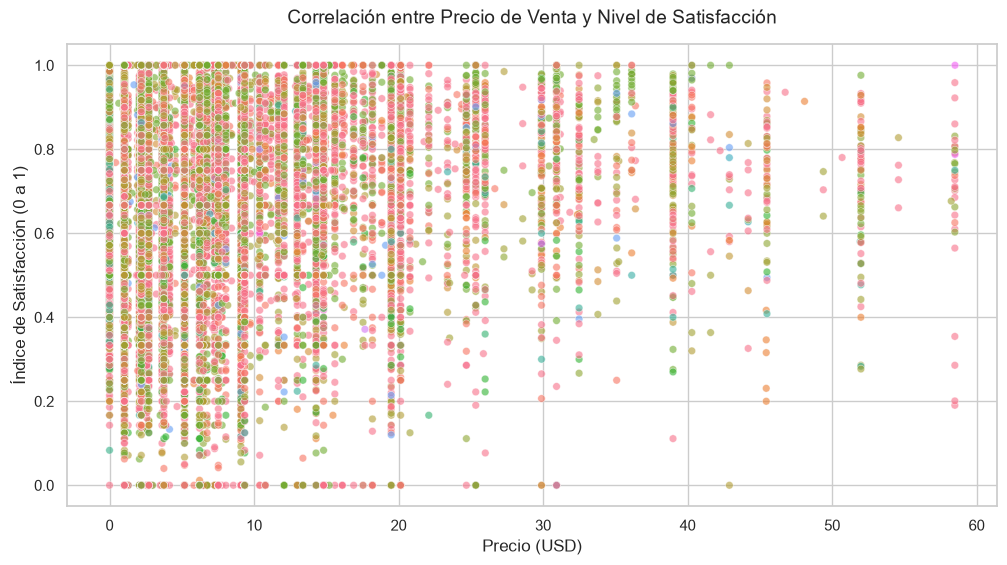

In [ ]:
plt.figure(figsize=(12, 6))

df_scatter = df[df['Precio usd'] <= 60]

# Mapeamos el color por género para mantener la estética colorida en los puntos
sns.scatterplot(data=df_scatter, x='Precio usd', y='Indice de satisfaccion', 
                hue='Genero principal', palette='husl', alpha=0.6, s=30, legend=False)

plt.title('Correlación entre Precio de Venta y Nivel de Satisfacción', fontsize=14, pad=15)
plt.xlabel('Precio (USD)', fontsize=12)
plt.ylabel('Índice de Satisfacción (0 a 1)', fontsize=12)
plt.show()

**Confirmación Estadística:** Como se observa en el gráfico anterior, la densidad de los datos hace que sea complicado identificar a simple vista si existe una tendencia ascendente o descendente. Para eliminar la ambigüedad visual y obtener una respuesta definitiva, recurriremos a un **Mapa de Calor (Heatmap) de correlación de Pearson**. Esta herramienta matemática cruzará el precio y la satisfacción (junto con otras variables numéricas) devolviéndonos un valor exacto entre -1 (correlación inversa) y 1 (correlación directa perfecta).

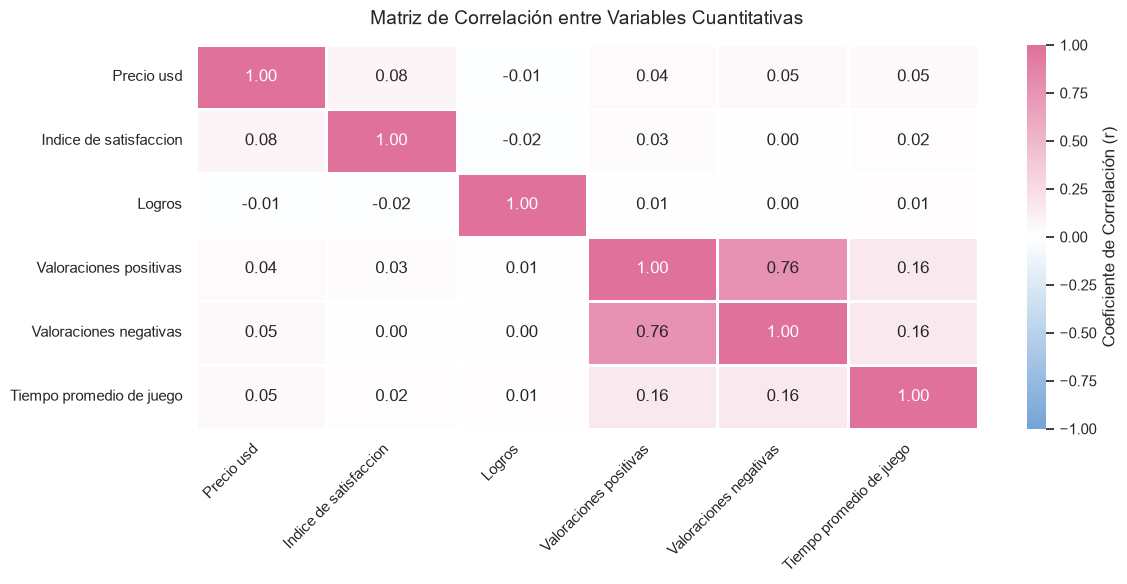

In [ ]:
# Importamos la clase LinearSegmentedColormap para crear un mapa de colores personalizado
from matplotlib.colors import LinearSegmentedColormap

plt.figure(figsize=(12, 6))

# Seleccionamos las variables numéricas clave para la matriz
columnas_interes = [
    'Precio usd', 
    'Indice de satisfaccion', 
    'Logros', 
    'Valoraciones positivas', 
    'Valoraciones negativas', 
    'Tiempo promedio de juego'
]

# Calculamos la matriz de correlación de Pearson
matriz_correlacion = df[columnas_interes].corr()

# Definimos paleta de colores
color_negativo = '#73A4D6'  
color_neutro = '#FFFFFF'    
color_positivo = '#DF719A'  

# Creamos una variable para la paleta de colores 
mi_gradiente = LinearSegmentedColormap.from_list('custom_cmap', [color_negativo, color_neutro, color_positivo])

# Generamos el Heatmap
sns.heatmap(
    matriz_correlacion, 
    annot=True, 
    fmt='.2f', 
    cmap=mi_gradiente, 
    vmin=-1, 
    vmax=1, 
    linewidths=0.8,
    cbar_kws={'label': 'Coeficiente de Correlación (r)'}
)

plt.title('Matriz de Correlación entre Variables Cuantitativas', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**Pregunta de investigación 2: ¿Existe una relación directa o correlación lineal entre el precio de un videojuego y el nivel de satisfacción de los jugadores?**

**Respuesta:** Como pudimos observar en el gráfico de dispersión (Scatter Plot) los puntos forman una nube plana sin una dirección clara. Esto es validado estadísticamente por el Mapa de Calor, el cual arroja un coeficiente de Pearson de **0.08** al cruzar ambas variables. La combinación de la exploración visual y la matriz matemática confirma de manera contundente que **no existe una relación lineal directa entre el precio de un videojuego y el nivel de satisfacción de los jugadores**. Los jugadores de Steam evalúan los juegos en función de sus propias expectativas y del valor entregado, no de lo que pagaron. Es posible encontrar juegos gratuitos con altísima aceptación y juegos de precio premium (60 USD) con reseñas mayoritariamente negativas.

##### **Visualización 4: Evolución de Lanzamientos**

**Pregunta de investigación 3: ¿En qué período anual se produjo la mayor aceleración histórica en la cantidad de lanzamientos dentro de la plataforma Steam?**

`*Nota analítica:*` En la siguiente visualización decidimos mantener el año 2019. Sin embargo, es fundamental aclarar que el dataset finaliza su recolección de datos a mediados de dicho año. Por consiguiente, la drástica caída que se observa al final de la serie temporal es una "falsa caída" producto de datos incompletos, y no representa una contracción real de las publicaciones en la plataforma.

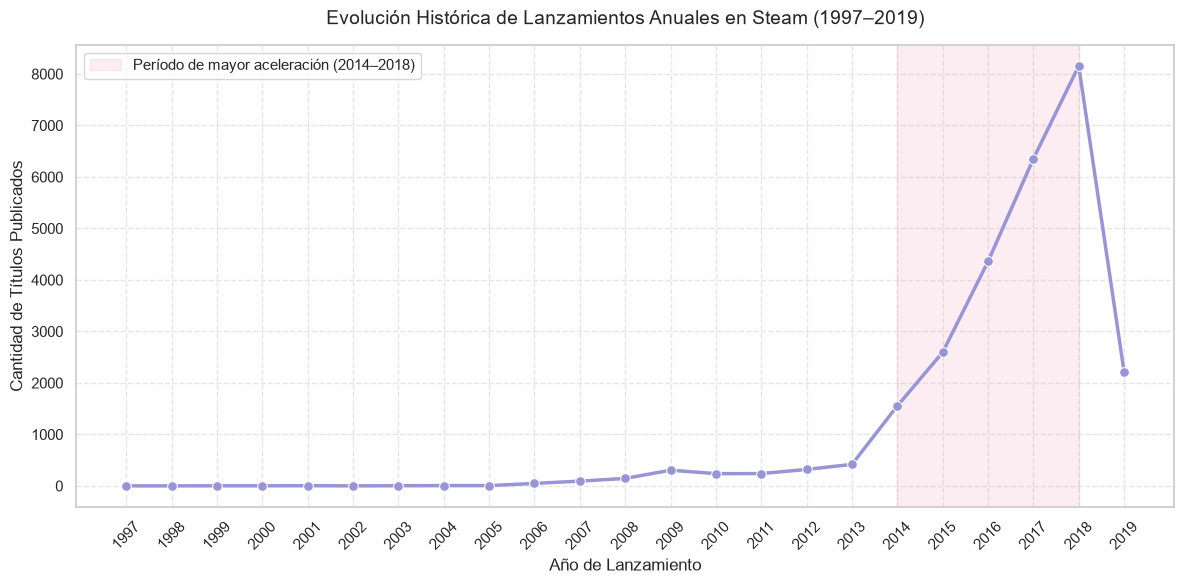

In [ ]:
plt.figure(figsize=(12, 6))

# Agrupamos por año y contamos la cantidad de títulos
lanzamientos_anuales = df.groupby('Año de lanzamiento').size().reset_index(name='Cantidad de lanzamientos')

# Extraemos colores de la paleta 
color_linea = "#9895D7"    
color_sombreado = "#E98BA6"

# Gráfico de línea temporal
sns.lineplot(
    data=lanzamientos_anuales, 
    x='Año de lanzamiento', 
    y='Cantidad de lanzamientos', 
    marker='o', 
    color=color_linea, 
    linewidth=2.5,
    markersize=7
)

plt.title('Evolución Histórica de Lanzamientos Anuales en Steam (1997–2019)', fontsize=14, pad=15)
plt.xlabel('Año de Lanzamiento', fontsize=12)
plt.ylabel('Cantidad de Títulos Publicados', fontsize=12)
plt.xticks(lanzamientos_anuales['Año de lanzamiento'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)

# Destacar el período de aceleración exponencial (2014-2018)
plt.axvspan(2014, 2018, color=color_sombreado, alpha=0.15, label='Período de mayor aceleración (2014–2018)')
plt.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


**Pregunta de investigación 3: ¿En qué período anual se produjo la mayor aceleración histórica en la cantidad de lanzamientos dentro de la plataforma Steam?**

**Respuesta:** El gráfico de tendencia evidencia claramente que la mayor aceleración histórica se produjo **entre los años 2014 y 2018** (área sombreada). Durante esos cuatro años, la curva rompe su crecimiento moderado previo y se vuelve exponencial. Este salto masivo en la publicación de títulos coincide directamente con la implementación de políticas de distribución abierta por parte de Valve (como Steam Direct), democratizando y facilitando el acceso de desarrolladores independientes a la tienda global.

### Conlusiones Finales

Tras aplicar diversas técnicas de limpieza, transformación y visualización de datos utilizando Pandas, NumPy y Matplotlib/Seaborn, hemos logrado explorar en profundidad el catálogo histórico de la tienda Steam. A continuación, damos respuesta formal a nuestras tres preguntas de investigación iniciales:

#### Conclusiones de las preguntas de investigación

**1. ¿Qué género de videojuego concentra el mayor porcentaje promedio de reseñas positivas?**

Descubrimos que los géneros considerados "de nicho", como los RPG, Simuladores y de Estrategia, tienden a liderar los índices de satisfacción. Esto se debe probablemente a que apuntan a comunidades de jugadores más dedicadas y con expectativas muy específicas. Por otro lado, géneros masivos como "Acción" presentan índices de satisfacción promedios ligeramente inferiores, sufriendo el impacto de un mayor volumen de críticas y una saturación de lanzamientos de calidad mixta.

**2. ¿Existe una relación directa o correlación lineal entre el precio de un videojuego y el nivel de satisfacción de los jugadores?**

No, no existe ninguna relación lineal. Tanto el análisis visual (gráfico de dispersión) como el análisis estadístico (mapa de calor con un coeficiente de Pearson de 0.08) confirmaron que el precio no es un indicador de la calidad percibida. El mercado de Steam valora fuertemente la relación costo-beneficio, premiando a juegos gratuitos o económicos con reseñas perfectas, y castigando severamente a juegos "Premium" que no cumplen con las expectativas.

**3. ¿En qué período anual se produjo la mayor aceleración histórica en la cantidad de lanzamientos?**

El análisis de series temporales reveló que el gran salto exponencial en la plataforma ocurrió entre los años 2014 y 2018. Este período de aceleración masiva coincide con la democratización de la tienda gracias a políticas de Valve como "Steam Greenlight" y "Steam Direct", las cuales abrieron las puertas a miles de desarrolladores independientes.

**Investigación adicional para responder la pregunta 3**

La mención a Steam Greenlight y Steam Direct proviene de la investigación que realizamos para comprender qué medidas y cambios estructurales se implementaron que pudieran ocasionar este salto exponencial entre los años 2014 y 2018.
En relación a esto notamos que Steam Greenlight (que estuvo activo desde el 2012 al 2017) permitía que la comunidad votara qué títulos ingresaban a la plataforma, los que disparó las publicaciones independientes entre 2014 y 2016.
Desde el 13 de junio del 2017, entra en vigencia Steam Direct, que reemplazó el sistema por una tarifa fija de $100 USD sin votación previa, lo que causó el récord absoluto de lanzamientos registrado en 2018.

Enlace a la noticia:

https://steamcommunity.com/greenlight/

https://steamcommunity.com/games/593110/announcements/detail/1328973169870947116

#### Resumen de Hallazgos Técnicos

El uso de Pandas fue crucial para limpiar un dataset con más de 27.000 filas, permitiéndonos crear variables derivadas vitales como el "Índice de satisfacción" o el año de lanzamiento. Por su parte, la creación de funciones estadísticas personalizadas con NumPy nos permitió descubrir la fuerte asimetría del mercado: la media y la desviación estándar de las valoraciones nos mostraron que el éxito en Steam está altamente concentrado; un porcentaje muy pequeño de juegos acumula la inmensa mayoría de las interacciones y ventas.

#### Limitaciones del Dataset

Luego del análisis realizado de todo el dataset, reconocemos que el mismo presenta las siguientes limitaciones:
* **Temporalidad:** Los datos abarcan únicamente hasta mediados de 2019, por lo que no reflejan el estado actual del mercado post-pandemia y tampoco permitió hacer conclusiones y comparaciones sobre el año 2019.
* **Sesgo de participación:** Las reseñas son voluntarias, lo que tiende a sobrerrepresentar las opiniones extremas (muy positivas o muy negativas).
* **Estimación de ventas:** La columna "Propietarios" se expresa en rangos muy amplios, limitando la precisión de cualquier cálculo de ingresos.
* **Conversión monetaria:** Transformamos el precio original de GBP a USD utilizando una tasa fija, sin contemplar la inflación, los precios regionales o los históricos de descuentos (Steam Sales).


#### Futuros pasos



* **Actualización temporal:** Cruzar la base histórica con registros recientes para evaluar el impacto de la pandemia y el crecimiento del mercado post-2019.
* **Cuantificación de la variable Propietarios:** Reemplazar los intervalos categóricos actuales por valores numéricos continuos (mediante el punto medio de cada rango). Esta conversión habilitará cálculos financieros como por ejemplo la estimación de ingresos brutos (Precio usd × Propietarios estimados) y permitirá ponderar el nivel de satisfacción de acuerdo al volumen real de copias vendidas.
* **Tratamiento de las etiquetas SteamSpy:** Tratar y desagregar la columna **Etiquetas SteamSpy** mediante técnicas de análisis multietiqueta para descubrir nichos y micro-tendencias (como por ejemplo juegos de Zombies, Supervivencia, etc.) que los géneros principales no logran capturar.

### Exportación de resultados

HOLA SOY JOHA
Finalmente, exportamos nuestro DataFrame enriquecido (sin nulos y con las nuevas columnas calculadas) a un nuevo archivo CSV para facilitar futuros análisis sin necesidad de repetir los procesos de limpieza.

In [1]:
# Guardamos el dataframe en un nuevo archivo CSV, excluyendo el índice de Pandas
df.to_csv('steam_procesado.csv', index=False)

print("¡Exportación exitosa! El archivo 'steam_procesado.csv' ha sido creado.")

NameError: name 'df' is not defined

In [ ]:
df[[ "Precio", "Precio usd", "Precio_usd_norm"]].head()

,Precio,Precio usd,Precio_usd_norm
0,7.19,9.35,0.017044
1,3.99,5.19,0.009461
2,3.99,5.19,0.009461
3,3.99,5.19,0.009461
4,3.99,5.19,0.009461


Presentación del proyecto

Título, integrantes, descripción del dataset, justificación de elección y objetivo de predicción.



Carga y exploración inicial

Librerías, lectura del CSV, dimensiones, tipos de datos, valores nulos y estadísticas descriptivas.



Análisis de variables

Identificación de X e Y, distribuciones, relaciones y matriz de correlación.



Limpieza y preparación

Tratamiento de nulos, variables categóricas y conversión a estructura matricial.



Partición de datos

Separación en entrenamiento (80 %) y test (20 %), como en el ejemplo del profesor.



Entrenamiento del modelo

Regresión lineal múltiple con LinearRegression.



Evaluación del modelo

Métricas R², MAE y RMSE, comparación entre entrenamiento y test, predicciones y gráficos de errores.



Interpretación de coeficientes

Influencia de las variables sobre la predicción y análisis de su importancia.



Conclusiones finales

Respuestas a las cuatro preguntas obligatorias de la pauta, limitaciones y posibles mejoras.